For Project 3, I chose data set 6.

This is part 2 of the project.

In [2]:
import numpy as np

DATA_FILE = "/Users/luisrojascastillo/Downloads/Project3_set6.txt"

energies = np.loadtxt(DATA_FILE)
N = energies.size

print(f"Data set: Project 3, set 6 data")
print(f"Total number of entries, N = {N}")
print(f"Min energy = {energies.min():.4f}")
print(f"Max energy = {energies.max():.4f}")
print(f"Mean energy = {energies.mean():.4f}")

Data set: Project 3, set 6 data
Total number of entries, N = 334
Min energy = 0.2482
Max energy = 3166.2319
Mean energy = 121.8710


This is just a simple program that just reads the file for dataset 6.  There are 334 entries, which is $N$. As stated in the project description, we don't have $n_s$ or $n_b$, but at least we know that $334 = n_s + n_b$.

Then here is part 3, which is the histogram.

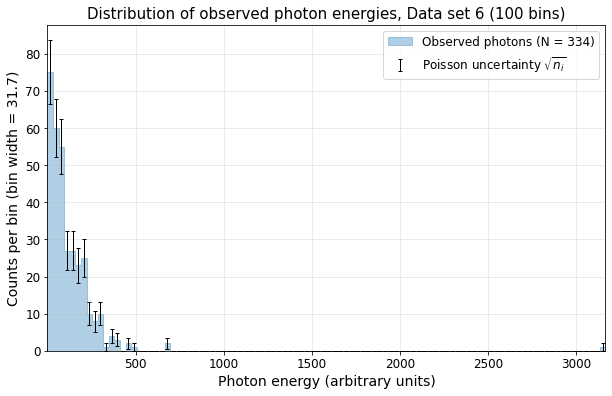

In [3]:
import matplotlib.pyplot as plt

DATA_FILE = "/Users/luisrojascastillo/Downloads/Project3_set6.txt"
N_BINS = 100

energies = np.loadtxt(DATA_FILE)
N = energies.size

# Bin the data
counts, edges = np.histogram(energies, bins=N_BINS)
centers = 0.5 * (edges[:-1] + edges[1:])
bin_width = edges[1] - edges[0]
errors = np.sqrt(counts) # this is the Poisson uncertainty on each bin

fig, ax = plt.subplots(figsize=(10,6))

ax.hist(energies, bins=edges, histtype="stepfilled", color="tab:blue", alpha=0.35, edgecolor="tab:blue", label=f"Observed photons (N = {N})")
ax.errorbar(centers, counts, yerr=errors, fmt="none", ecolor="black", elinewidth=1, capsize=2, label=r"Poisson uncertainty $\sqrt{n_i}$")

ax.set_xlabel("Photon energy (arbitrary units)", fontsize=14)
ax.set_ylabel(f"Counts per bin (bin width = {bin_width:.1f})", fontsize=14)
ax.set_title("Distribution of observed photon energies, Data set 6 (100 bins)", fontsize=15)
ax.tick_params(labelsize=12)
ax.set_xlim(edges[0], edges[-1])
ax.set_ylim(bottom=0)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)

In the histogram, the 100 bin counts add up to 334, so every photon landed in a bin and none were lost or double counted. Additiojnally, the bin counts match the raw data, like when there are 75 photons in between 0.2 and 31.9, and when 60 are in between 31.9 and 63.6.

It looks a little squeezed because np.histogram with bins=100 splits the range from the smallest value to the largest value into 100 equal bins, so the smallest is 0.25 and the largest is 3166.2, so each bin is about 31.7 wide.

Also, the one photon at 3166.2 is the only value above 700, which makes it a massive outlier, which is why the graph looks "squeezed".

Now we move on to part 4, which was a bit long

In [4]:
from scipy.optimize import minimize

# Fixed shape parameters from the project 2 maximum-likelihood fit
E0 = 206.0
GAMMA = 21.84
EB = 100.0

energies = np.loadtxt(DATA_FILE)
N = energies.size

fs = 1.0 / (np.pi * GAMMA * (1.0 + ((energies - E0) / GAMMA) **2))
fB = np.exp(-energies / EB) / EB

def m2lnL(params):
    ns = params[0]
    f = (ns / N) * fs + ((N - ns) / N) * fB
    return -2.0 * np.sum(np.log(f))

# Initial guess of 37 photons clustered near 210 as shown in the histogram
ns0 = [40.0]

# Bounded fit
result = minimize(m2lnL, ns0, bounds=[(0.0, N)])

ns_hat = result.x[0]
nb_hat = N - ns_hat

print("=== Bounded fit (0 <= ns <= N) ===")
print(f"Converged: {result.success} - {result.message}")
print(f"N = {N}")
print(f"ns = {ns_hat:.2f} (best-fit number of signal photons)")
print(f"nb = {nb_hat:.2f} (= N - ns)")
print(f"-2 ln L at minimum = {result.fun:.3f}")

# For a comparison with -2 ln L with no signal at all (ns = 0)
print(f"-2 ln L at ns = 0 = {m2lnL([0.0]):.3f}")

=== Bounded fit (0 <= ns <= N) ===
Converged: True - CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
N = 334
ns = 27.21 (best-fit number of signal photons)
nb = 306.79 (= N - ns)
-2 ln L at minimum = 3843.296
-2 ln L at ns = 0 = 3890.352


I used the fixed shape parameters from project 2, specifically on the part that focused on using the maximum-likelihood fit. 

From that, I got a best fit value of $n_s$ to be 27.21

Okay, so because $N = 334$ is fixed, $n_b = N - n_s$ is not a separate free parameter, and this is because of the same ordinary likelihood that was used in project 2.

The likelihood is the product of $f(E_i)$ over all 334 photons. Taking logs turns the product into a sum, which is much easier to work with. Multiplying by -2 turns the "find the maximum" into "find the minimum", which is what the minimize function does.

I started guessing at $n_s = 40$ based on the fact that roughly that amount of photons are clustered near 210 in the histogram.

Okay, so for the "mistake on purpose" part, I did the following:

In [5]:
print()
print("=== Unbounded fit ===")

# Attempt 1: no bounds, starting guess from ns = 40
result_a = minimize(m2lnL, [40.0])

print("Starting guess ns = 40")
print("Converged:", result_a.success, "-", result_a.message)
print(f"ns = {result_a.x[0]:.2f}")
print(f"-2 ln L = {result_a.fun:.3f}")
print()

# Attempt 2: no bounds, starting guess ns = -20 
result_b = minimize(m2lnL, [-20.0])

print("Starting guess ns = -20")
print("Converged:", result_b.success, "-", result_b.message)
print('ns =', result_b.x[0])
print("-2 ln L =", result_b.fun)
print()


=== Unbounded fit ===
Starting guess ns = 40
Converged: True - Optimization terminated successfully.
ns = 27.21
-2 ln L = 3843.296

Starting guess ns = -20
Converged: False - NaN result encountered.
ns = -20.0
-2 ln L = nan



/var/folders/lc/khdfnsgs41db7k05py3cybq80000gn/T/ipykernel_21275/553878319.py:17: RuntimeWarning: invalid value encountered in log
  return -2.0 * np.sum(np.log(f))


Since I used a negative number of photons for attempt 2, I got what I was looking for, which was a breakdown of the code's behavior. This is because the likelihood is NaN right at the start, so the fit can't take a single step, so the code just reports Converged: False" and stays at -20.

Looking at the photon with the highest energy, which is $E = 3166.2$, I wrote this, which works out the signal and background pdfs for that one photon, and then plugs the $n_s = -20$ into the mixture formula:

$f = (\frac{n_s}{N})\cdot f_s + (\frac{N - n_s}{N})\cdot f_B = -\frac{20}{334} (8 \times 10^{-7}) + (\text{tiny}) \approx -4.75 \times 10^{-8}$

In [6]:
E_max = energies.max()
fs_max = 1.0 / (np.pi * GAMMA * (1.0 + ((E_max - E0) / GAMMA) ** 2))
fB_max = np.exp(-E_max / EB) / EB

print(f"Highest-energy photon: E = {E_max:.1f}")
print(f"Signal pdf there: fs = {fs_max:.2e}")
print(f"Background pdf there: fB = {fB_max:.2e}")

Highest-energy photon: E = 3166.2
Signal pdf there: fs = 7.93e-07
Background pdf there: fB = 1.78e-16


In [7]:
# Plugging n_s = -20 into f for that one photon at 3166
ns_bad = -20.0
f_bad = (ns_bad / N) * fs_max + ((N - ns_bad) / N) * fB_max
print(f"f(E = {E_max:.1f}) with ns = -20: {f_bad:.2e} (negative, so ln f is NaN)")


f(E = 3166.2) with ns = -20: -4.75e-08 (negative, so ln f is NaN)


That's how we can see the negative probability density, which is impossible, and its log is undefined. A single NaN term makes the whole sum NaN, so the fit is broken.

From this, it means that the bound $0 \leq n_s \leq N$ isn't just something random, but a minimizer that can step into $-n_s$, where the likelihood stops being valid and the fit collapses.

Moving on to part 5, which was plotting a histogram for the nth time.

Text(0.5, 1.0, 'Zoomed in: E < 700 a.u. (1 photon not shown)')

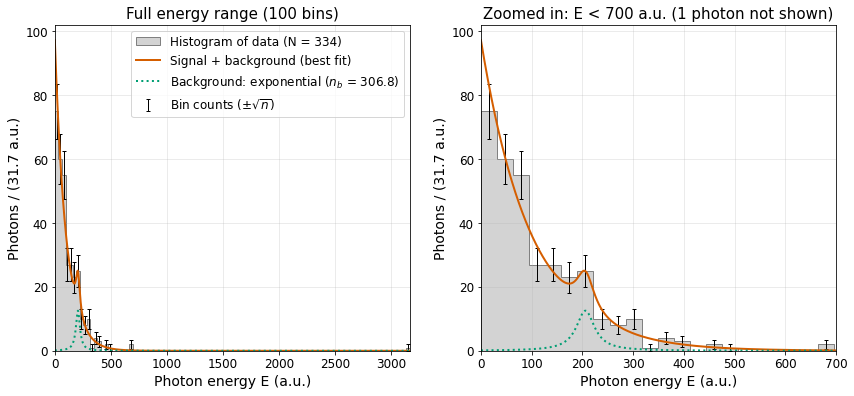

In [8]:
def signal_pdf(E):
    return 1.0 / (np.pi * GAMMA * (1.0 + ((E - E0)/GAMMA)**2))

def background_pdf(E):
    return np.exp(-E / EB) / EB

def m2lnL(params):
    ns = params[0]
    f = (ns / N) * signal_pdf(energies) + ((N - ns) / N) * background_pdf(energies)
    return -2.0 * np.sum(np.log(f))

result = minimize(m2lnL, [40.0], bounds=[(0.0, N)])
ns_hat = result.x[0]
nb_hat = N - ns_hat

# This has the same 100 bins as before
counts, edges = np.histogram(energies, bins=N_BINS)
centers = 0.5 * (edges[:-1] + edges[1:])
bin_width = edges[1] - edges[0]
errors = np.sqrt(counts)

# Best fit curves
E_curve = np.linspace(0.0, edges[-1], 20000)
signal_curve = ns_hat * signal_pdf(E_curve) * bin_width
background_curve = nb_hat * background_pdf(E_curve) * bin_width
total_curve = signal_curve + background_curve

# This is tfor the left panel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,6))

for ax in [ax1, ax2]:
    ax.hist(energies, bins=edges, histtype="stepfilled", color="lightgray", edgecolor="gray", label=f"Histogram of data (N = {N})")
    ax.errorbar(centers[counts > 0], counts[counts > 0], yerr=errors[counts > 0], fmt="none", ecolor="black", elinewidth=1, capsize=2, label=r"Bin counts ($\pm\sqrt{n})$")
    ax.plot(E_curve, total_curve, color="#D55E00", linewidth=2, label="Signal + background (best fit)")
    ax.plot(E_curve, signal_curve, color="#009E73", linewidth=2, linestyle=":", label=rf"Background: exponential ($n_b$ = {nb_hat:.1f})")
    ax.set_xlabel("Photon energy E (a.u.)", fontsize=14)
    ax.set_ylabel(f"Photons / ({bin_width:.1f} a.u.)", fontsize=14)
    ax.tick_params(labelsize=12)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)

ax1.set_xlim(0, edges[-1])
ax1.set_title("Full energy range (100 bins)", fontsize=15)
ax1.legend(fontsize=12)

ax2.set_xlim(0, 700)
ax2.set_title("Zoomed in: E < 700 a.u. (1 photon not shown)", fontsize=15)

In [9]:
print(f"ns = {ns_hat:.2f}")
print(f"nb = {nb_hat:.2f}")
print(f"Bin width = {bin_width:.2f} a.u.")
print(f"Height of signal curve at E0 = {ns_hat * signal_pdf(E0) * bin_width:.2f} photons ber bin")


ns = 27.21
nb = 306.79
Bin width = 31.66 a.u.
Height of signal curve at E0 = 12.56 photons ber bin


The two pdf functions (signal_pdf and background_pdf) are the same formulas from before, but written as functions because now they're being used on both the photons and the curves.

Regarding the histogram, these are the same 100 bins and $\sqrt{n}$ as before, and empty bins get no error bar, which is what the counts > 0 does.

The most important part here is that we are scaling the curves, and it is the same approach as done in part 2, where the expected counts per bin is

$\text{expected counts per bin} \approx n \cdot f(E) \cdot \Delta E$

A pdf has an area of 1, while the histogram's bars add up to 334 photons. Multiplying by the number of photons and the bin width (31.66) puts the curves on the same scale as the bars.

The total curve is just the sum of the signal and background curves.

The for loop runs the same drawing code once for each panel, so it doesn't have to be written more than once. After the loop, each panel gets its own $x$-range and title.

Basically, the plot shows the background and signal pdfs, where the background pdf is the dotted exponential that follows the overall fall of the data well, and the signal pdf is the dashed Wigner curve, and is a small bump centered at 206, where there are about 12.6 photons per bin at its peak.

In total, the solid curve follows the background, then rises to about 25 near $E = 206$, which matches the bin at 190-222 (for 25 counts).

Now we move on to part 6

In [10]:
fs = 1.0 / (np.pi * GAMMA * (1.0 + ((energies - E0) / GAMMA)**2))

def m2lnL(params):
    ns = params[0]
    f = (ns / N) * fs + ((N - ns) / N) * fB
    return -2.0 * np.sum(np.log(f))


# Signal + background hypothesis
result = minimize(m2lnL, [40.0], bounds=[(0.0, N)])
ns_hat = result.x[0]
m2lnL_sb = result.fun

# Background-only
m2lnL_b = m2lnL([0.0])

TS = m2lnL_b - m2lnL_sb

print(f"Best-fit ns = {ns_hat:.2f}")
print(f"-2 ln L (signal + background) = {m2lnL_sb:.3f}")
print(f"-2 ln L (background only) = {m2lnL_b:.3f}")
print(f"TS = {TS:.3f}")
print()

# How much of TS does each photon contribute?
f_best = (ns_hat / N) * fs + ((N - ns_hat) / N) * fB
TS_per_photon = 2.0 * np.log(f_best / fB)

print(f"Check: sum of the per-photon contributions = {np.sum(TS_per_photon):.3f}")
print()

print("The 5 photons that contribute the most to TS:")
order = np.argsort(TS_per_photon)[::-1]
for i in order[:5]:
    print(f" E = {energies[i]:8.2f} contributes {TS_per_photon[i]:6.2f}")
print()

# Expected number of photons this far out if there were only background
E_max = energies.max()
print(f" Expected number of background photons above E = {E_max:.0f}: " f"{N * np.exp(-E_max / EB):.1e}")


Best-fit ns = 27.21
-2 ln L (signal + background) = 3843.296
-2 ln L (background only) = 3890.352
TS = 47.056

Check: sum of the per-photon contributions = 47.056

The 5 photons that contribute the most to TS:
 E =  3166.23 contributes  39.43
 E =   208.50 contributes   1.24
 E =   207.87 contributes   1.24
 E =   207.78 contributes   1.24
 E =   207.07 contributes   1.24

 Expected number of background photons above E = 3166: 5.9e-12


Okay, so from here, we see that $TS = 47.056$ for set 6, but one photon, which is at $E \approx 3166$, contributes 39.43 of that. Unfortunately, this makes it very hard to answer ``is there a signal?" until we compare it to the null hypothesis.

As shown in the code, TS is calculated via

$TS = 2 \ln(L_\text{sig} + \text{bckg} / L_\text{bckg}) = (-2 \ln L \text{ at } n_s = 0) - (-2 \ln L \text{ at the best-fit } n_s)$

Where the max in the formula just means using the best-fit $n_s$, which was already found in part 4.

Additionally, looking deeper at this, we see that because the log turns a pdocut into a sum, TS is a sum over photons, so we can see how each one adds.

Simply doing $39.43/47.056$, we see that $83.8\%$ of TS comes from the single photon at 3166.

The best-fit $n_s$ with all 334 photons is 27.21, with a TS of $\approx 47.06$, however, the best-fit with 333 photons, excluding the photon at 3166, is 23.62, with a TS of 7.76. 

This comparison shows how consequential the 3166 photon is in the dataset.

Okay, so from this, we can see tat since Wigner has long tails, a signal photon can land that far out, with a probability of about $0.23\%$ per signal photon. With about 27 signal photons, we can expect about 0.06 of them up here. It's unlikely, but about 10 billion times more likely than the background explanation, which is why it adds so much to the TS.

The test can only compare these two hypotheses, it can't tell us if that photon comes from something neither model describes, such as an error in measurement or a background with a longer tail than an exponential.

Okay, now moving on to part 7.

In [11]:
N_EXPERIMENTS = 10000
OUTPUT_FILE = "simulated_experiments.npy"

# Every simulated experiment should have the same number of photons as the actual data
N = np.loadtxt(DATA_FILE).size

# A fixed seed allows for the same simulated experiments each time the code runs
rng = np.random.default_rng(seed=6)

simulated = rng.exponential(scale=EB, size=(N_EXPERIMENTS, N))

# Saves the experiments so other parts can use them
np.save(OUTPUT_FILE, simulated)

print(f"Shape of array = {simulated.shape} (experiments, photons per experiment)")
print(f"Total simulated photons = {simulated.size}")
print(F"Mean energy = {simulated.mean():.3f} (expected {EB})")
print(f"Standard deviation = {simulated.std():.3f} (expected {EB})")
print(f"Lowest energy = {simulated.min():.5f}")
print(f"Highest energy in any experiment = {simulated.max():.1f}")
print()
print(f"First experiment, first 5 photons: {np.round(simulated[0, :5], 2)}")

Shape of array = (10000, 334) (experiments, photons per experiment)
Total simulated photons = 3340000
Mean energy = 99.885 (expected 100.0)
Standard deviation = 99.778 (expected 100.0)
Lowest energy = 0.00001
Highest energy in any experiment = 1486.9

First experiment, first 5 photons: [69.13 18.35 60.27 53.59 73.47]


Since the null hypothesis says that there's no signal, every photon comes from the background pdf. This means $n_s = 0$ and the Wigner isn't used here. 

Additionally, since the script reads the file only to get $N = 334$, every simulated experiment must have the same number of photons as the real one.

To generate the data, I put rng.exponential(scale=EB, size=(N_EXPERIMENTS, N)), which draws all the energies at once into a table:

$\cdot$ each row is one simulated experiment

$\cdot$ each column is one photon

Which is why simulated[0] is the first experiment, and simulated[0,:5] is its first 5 recorded photons.

Since an exponential distribution has a mean and a standard deviation that is both equal to $E_b$, and since both came out very close to 100, that was the tell-tale sign that the simulation follows the right distribution.

Moving on to part 8, which is the maximum likelihood method

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

DATA_FILE = "/Users/luisrojascastillo/Downloads/Project3_Set6.txt"
SIM_FILE = "simulated_experiments.npy"

N_TO_FIT = 10000

# Fixed shape parameters taken from project 2's maximum likelihood fit
E0 = 206.0  # Wigner peak position
GAMMA = 21.84   # Wigner width
EB = 100.0  # exponential background scale

energies = np.loadtxt(DATA_FILE)
N = energies.size
simulated = np.load(SIM_FILE)[:N_TO_FIT]

def signal_pdf(E):
    return 1.0 / (np.pi * GAMMA * (1.0 + ((E - E0)/GAMMA) **2))

def background_pdf(E):
    return np.exp(-E/EB) / EB

def m2lnL(params, E):
    ns = params[0]
    f = (ns / N) * signal_pdf(E) + ((N - ns) / N) * background_pdf(E)
    return -2.0 * np.sum(np.log(f))

For the numpy and matplotlib and so on, I didn't have to reiterate them, but I think it's been a while since I integrated them, so I just implemented them again as a reminder that they are still activated.

Fits done = 10000, fits that did not converge = 8
ns in the real data = 27.21
Simulated experiments with ns = 0 (below 0.01): 6422
Median simulated ns = 0.00
Mean simulated ns = 1.97
Largest simulated ns = 40.00
Simulated experiments with ns >= 27.21: 2


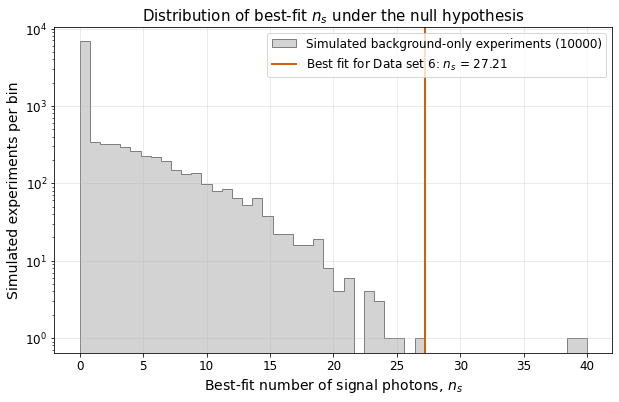

In [13]:
# Real data
result_data = minimize(m2lnL, [40.0], args=(energies,), bounds=[(0.0, N)])
ns_data = result_data.x[0]

# Simulated experiments
ns_sim = np.zeros(N_TO_FIT)
TS_sim = np.zeros(N_TO_FIT)
n_failed = 0

for i in range(N_TO_FIT):
    E = simulated[i]
    result = minimize(m2lnL, [40.0], args=(E,), bounds=[(0.0, N)])
    ns_sim[i] = result.x[0]
    TS_sim[i] = m2lnL([0.0], E) - result.fun
    if not result.success:
        n_failed += 1

# Save results for future parts of the project
np.save("ns_simulated.npy", ns_sim)
np.save("TS_simulated.npy", TS_sim)

print(f"Fits done = {N_TO_FIT}, fits that did not converge = {n_failed}")
print(f"ns in the real data = {ns_data:.2f}")
print(f"Simulated experiments with ns = 0 (below 0.01): {np.sum(ns_sim < 0.01)}")
print(f"Median simulated ns = {np.median(ns_sim):.2f}")
print(f"Mean simulated ns = {np.mean(ns_sim):.2f}")
print(f"Largest simulated ns = {np.max(ns_sim):.2f}")
print(f"Simulated experiments with ns >= {ns_data:.2f}: {np.sum(ns_sim >= ns_data)}")

# plot distribution of ns
fig, ax = plt.subplots(figsize=(10,6))

ax.hist(ns_sim, bins=50, histtype="stepfilled", color="lightgray", edgecolor="gray", label=f"Simulated background-only experiments ({N_TO_FIT})")
ax.axvline(ns_data, color="#D55E00", linewidth=2, label=rf"Best fit for Data set 6: $n_s$ = {ns_data:.2f}")
ax.set_xlabel(r"Best-fit number of signal photons, $n_s$", fontsize=14)
ax.set_ylabel("Simulated experiments per bin", fontsize=14)
ax.set_title(r"Distribution of best-fit $n_s$ under the null hypothesis", fontsize=15)
ax.set_yscale("log")
ax.tick_params(labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)

When looking at the fit, we can see that the logic is quite similar to part 4 of the project. The likelihood is unchanged, except for m2lnL, which now also takes the photon energies $E$. This lets one function work for both the rea data and any simulated experiment, and $\text{args}=(E,)$ is how minimize passes them in.

The for loop simply takes one row of the table from part 7, runs the fit, and then stores the result 10,000 times.

The code also calculates TS for each experiment, which will be useful for the other parts of the project after this one. Additionally, one bin holds about 6700 experiments, while others hold just 1, so on a normal axis, the tail would be invisible. Each gridline on the $y$-axis is 10 times the one below it.

The plot itself shows a spike at 0, and then experiences a "stair-case" like descent. The tail is just a bunch of random fluctuations that can still mimic a signal, so $n_s$ reaches 7.3 in about $10\%$ of experiments, and 16.1 in about $1\%$. 

Now, we move on to part 9, with the light from the end of the tunnel now visible

In [14]:
ALPHA = 0.01 # probability of Type I error

I had to search up what exactly a Type I error was, and it is a type of error that happens when you reject a true null hypothesis in a statistical test. In other words, a false positive.

Simulated experiments = 10000
Simulated experiments with TS = 0: 6417
Largest simulated TS = 20.65

TS threshold for a 1% Type I error = 3.683
Check: fraction of simualted TS above the threshold = 0.0100

TS for Data set 6 = 47.056
Simulated experiments with TS >= 47.06: 0
p-value < 1/10000 = 1e-04

TS(data) is above the threshold: reject the null hypothesis at the 1% level.


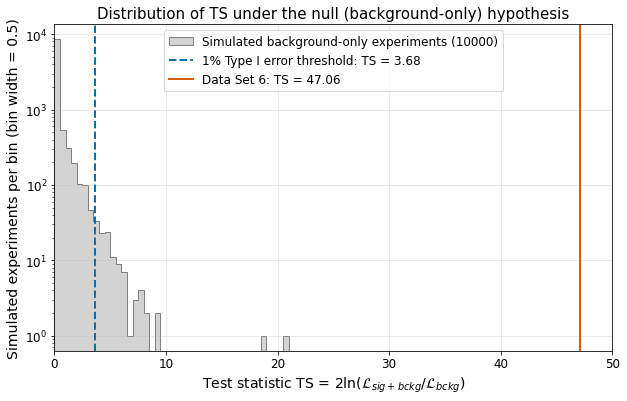

In [15]:
TS_FILE = "TS_simulated.npy"

E0 = 206.0
GAMMA = 21.84
EB = 100.0

energies = np.loadtxt(DATA_FILE)
N = energies.size
TS_sim = np.load(TS_FILE)
n_sim = TS_sim.size

def m2lnL(params, E):
    ns = params[0]
    fs = 1.0 / (np.pi * GAMMA * (1.0 + ((E - E0) / GAMMA) **2))
    fB = np.exp(-E/EB) / EB
    f = (ns / N) * fs + ((N - ns)/ N) * fB
    return -2.0 * np.sum(np.log(f))

# TS for real data (same as for part 6)
result = minimize(m2lnL, [40.0], args=(energies, ), bounds=[(0.0, N)])
TS_data = m2lnL([0.0], energies) - result.fun

# Threshold, of which 99% of the simulated TS valuesare below it
TS_threshold = np.percentile(TS_sim, 100 * (1 - ALPHA))

# p-value
n_above = np.sum(TS_sim >= TS_data)
p_value = n_above / n_sim

print(f"Simulated experiments = {n_sim}")
print(f"Simulated experiments with TS = 0: {np.sum(TS_sim < 1e-6)}")
print(f"Largest simulated TS = {TS_sim.max():.2f}")
print()
print(f"TS threshold for a 1% Type I error = {TS_threshold:.3f}")
print(f"Check: fraction of simualted TS above the threshold = {np.mean(TS_sim > TS_threshold):.4f}")
print()
print(f"TS for Data set 6 = {TS_data:.3f}")
print(f"Simulated experiments with TS >= {TS_data:.2f}: {n_above}")
if n_above == 0:
    print(f"p-value < 1/{n_sim} = {1 / n_sim:.0e}")
else:
    print(f"p-value = {p_value:.4f}")
print()
if TS_data > TS_threshold:
    print("TS(data) is above the threshold: reject the null hypothesis at the 1% level.")
else:
    print("TS(data) is below the threshold: we cannot reject the null hypothesis at the 1% level.")

# Plot the TS distribution with the threshold and the data value
fig, ax = plt.subplots(figsize=(10,6))

bins = np.linspace(0, 50, 101)
ax.hist(TS_sim, bins=bins, histtype="stepfilled", color="lightgray", edgecolor="gray", label=f"Simulated background-only experiments ({n_sim})")
ax.axvline(TS_threshold, color="#0072B2", linewidth=2, linestyle='--', label=f"1% Type I error threshold: TS = {TS_threshold:.2f}")
ax.axvline(TS_data, color="#D55E00", linewidth=2, label=f"Data Set 6: TS = {TS_data:.2f}")

ax.set_xlabel(r"Test statistic TS = $2\ln(\mathcal{L}_{sig+bckg}/\mathcal{L}_{bckg})$", fontsize=14)
ax.set_ylabel("Simulated experiments per bin (bin width = 0.5)", fontsize=14)
ax.set_title("Distribution of TS under the null (background-only) hypothesis", fontsize=15)
ax.set_yscale("log")
ax.set_xlim(0, 50)
ax.tick_params(labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)

What we see here is that there is a huge spike at TS = 0 again, with about $64\%$ of background-only experimentings having TS = 0. These are the same experiments where the best fit was $n_s = 0$ in part 8, since the two fits are then identical.

The tail falls off very quickly, and the largest simulated TS value is about 20.65. We also see that TS = 47.06, which was found in part 6, is more than twice as large as the simulated TS value, and 13 times the threshold of 3.68.

We see again that there is a photon at 3166 which contributes 39.4 of the TS value of 47.06, however, on top of that, we also see that the remaining TS value is reached by only 8 of the 10,000 background-only experiments. This is still above the $1\%$ threshold, so the conclusion doesn't depend on that one photon.

In the book, I think it states that a common shortcut assumes TS follows $\frac{1}{2} \chi^2$ with 1 degree of freedom, which predicts a threshold of 5.41 and that $50\%$ of experiments are at $TS = 0$.

My simulation gave a threshold of 3.68 and a rate of $64\%$ of experiments at $TS = 0$, which isn't that far off from what the book says, so it's pretty reasonable to say that we should use simulated experiments than just going through strict mathematics.

Now onto part 10

Yeah, the null hypothesis is indeed rejected. As shown in part 6 of the project, the TS of the data is 47.06, which is way above the threshold of 3.68.

The generally stated rule is that the null hypothesis is rejected if TS(data) > TS(threshold), and since this is held true, then the null hypothesis is rejected.

The p-value (<0.00001) is also much smaller than the $1\%$ significance level, which also leads to the null hypothesis being rejected.

What this can mean is that if the file contained only background, then we can expect a TS above 3.68 in only $1\%$ of the experiments. However, the TS I calculated is about 13 times larger than the threshold, and more than twice the largest value from any of the 10,000 background-only simulations. This then can be used as evidence of a Wigner signal in data set 6, with a set-fit $n_s \approx 27$ signal photons.

Now for part 11, which is the discussion question

$\textbf{Why did I ask you to use 10,000 simulated experiments?}$

The $1\%$ threshold is usually set by the most extreme $1\%$ of the simulated experiments, so its accuracy depends on how many experiments land in that percentage. In other words, with 10k experiments, only 100 lie above the threshold.

$\textbf{How would 100 simulated experiments be a bad idea?}$

The reason it would be a bad idea is because one experiment would decide the results, and with only 100 experiments, the $1\%$ threshold would be set by the single most extreme one, so the error on that $1\%$ is about $100\%$. Additionally, the threshold would jump around, and would vary from 1.86 to 6.08 depending on which set of 100 one would use for the 10k TS values. This basically makes the range quite worthless because it'd be too wide to make any reasonable interpretations.

$\textbf{How would 10,000,000 simulated experiments be a bad idea?}$

Well, since it takes about 15 seconds for 10,000 fits, for 10 million fits, which is 1,000 times longer, it'd be about 15k seconds, or over four hours. Additionally, the error on the threshold would shrink from about $10\%$ to roughly $0.3\%$, which is very precise, but more than what is being asked.

$\textbf{How many simulated experiments are the minimum you'd want to produce to reach this threshold?}$

Since $5\sigma$ is the one-sided tail probability of a normal distribution, then

$p(5\sigma) = 2.87 \times 10^{-7} \approx \text{1 in 3.5 million}$

The absolute minimum is about 3.5 million, which is 1/p, the number of experiments required to get just one above the $5\sigma$ threshold. Even then, the threshold would depend on a single experiment, which means that we'd encounter the same problem as using 100 experiments for $1\%$.

$\textbf{Ask yourself with honesty: did you see a signal `by eye' on step 3?}$

In all honesty, when I first looked at it, it didn't look like much of a signal to me. I just saw a quickly descending histogram, which seems to end at about 500 $E$, and then there is a single photon at $E = 3166$. Perhaps that could've been interpreted as a signal, but from my perspective, at the time, it really only looked like an outlier.

Now this is part 12. I get that I'm not a graduate student, but like last time, I like doing hard problems, so I chose to do question 12 regardless, even if I don't get credit for it ☹️

For this plot, the ROC curve is about the power at the $1\%$ threshold, and can also be called the true positive rate. Additionally, we need two sets of simulated experiments: Null experiments (background pdf only), and signal experiments (background plus $n_s$ signal photons).

Then, for every possible threshold $t$ on TS, the script calculates two numbers: $x$ = false positive rate (fraction of null experiments with $TS \geq t$), and $y$ = true positive rate (fraction of signal experiments with $TS \geq t$)

/var/folders/lc/khdfnsgs41db7k05py3cybq80000gn/T/ipykernel_21275/543192975.py:22: RuntimeWarning: divide by zero encountered in log
  return -2.0 * np.sum(np.log(f))


=== True ns = 27.21 ===
Median TS of the signal experiments = 10.45
Signal experiments with TS = 0: 0
Signal experiments with TS = infinity: 1
AUC (area under the ROC curve) = 1.0000
AUC check (random pairs) = 0.9930
Power at the 1% threshold (TS > 2.92) = 0.8900

=== True ns = 35.0 ===
Median TS of the signal experiments = 14.02
Signal experiments with TS = 0: 0
Signal experiments with TS = infinity: 0
AUC (area under the ROC curve) = 1.0000
AUC check (random pairs) = 0.9993
Power at the 1% threshold (TS > 2.92) = 0.9800



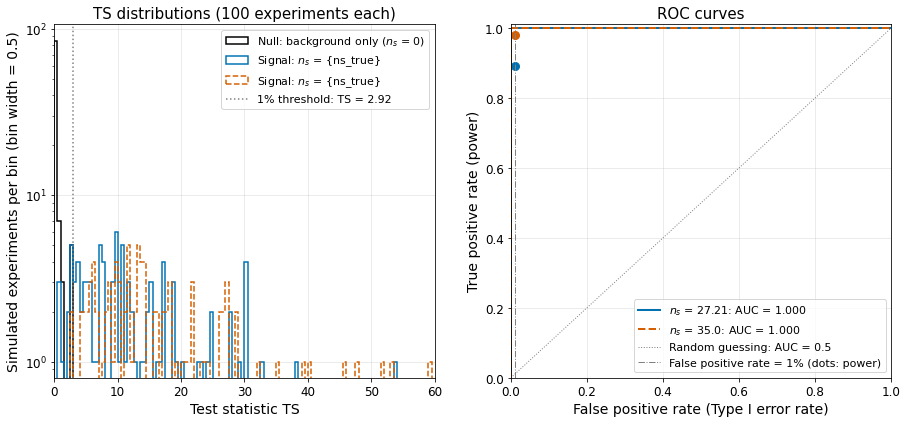

In [20]:
TS_NULL_FILE = "TS_simulated.npy" # TS of the 10k background-only

N_EXPERIMENTS = 100 # I used 100 when I first wrote this
NS_VALUES = [27.21, 35.0]
ALPHA = 0.01 # Type I error 

# Fixed shape parameters
E0 = 206.0
GAMMA = 21.84
EB = 100.0

N = np.loadtxt(DATA_FILE).size
TS_null = np.load(TS_NULL_FILE)[:N_EXPERIMENTS]

rng = np.random.default_rng(seed=12)

def m2lnL(params, E):
    ns = params[0]
    fs = 1.0 / (np.pi * GAMMA * (1.0 + ((E - E0) / GAMMA) ** 2))
    fB = np.exp(-E / EB) / EB
    f = (ns / N) * fs + ((N - ns) / N) * fB
    return -2.0 * np.sum(np.log(f))

def test_statistic(E):
    result = minimize(m2lnL, [40.0], args=(E,), bounds=[(0.0, N)])
    return m2lnL([0.0], E) - result.fun

def simulate_signal_experiment(ns_true):
    n_signal = rng.binomial(N, ns_true / N)
    n_background = N - n_signal

    # Bacground photons
    background = rng.exponential(scale=EB, size=n_background)

    # Signal photons
    signal = E0 + GAMMA * rng.standard_cauchy(size=n_signal)
    while np.any(signal < 0):
        negative = signal < 0
        signal[negative] = E0 + GAMMA * rng.standard_cauchy(size=np.sum(negative))

    return np.concatenate([signal, background])

def roc_curve(TS_null, TS_signal):
    thresholds = np.unique(np.concatenate([TS_null, TS_signal]))[::-1]
    fpr = [0.0] # threshold above every TS
    tpr = [0.0]
    for t in thresholds:
        fpr.append(np.mean(TS_null) >= t)
        tpr.append(np.mean(TS_signal >= t))
    return np.array(fpr), np.array(tpr)

def area_under_curve(x, y):
    return np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2.0)

# Threshold for a 1% type I error
TS_threshold = np.percentile(TS_null, 100 * (1 - ALPHA))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
colors = ["#0072B2", "#D55E00"]
styles = ["-", "--"]

bins = np.linspace(0, 60, 121)
ax1.hist(TS_null, bins=bins, histtype="step", color="black", linewidth=1.5, label=r"Null: background only ($n_s$ = 0)")

for k in range(len(NS_VALUES)):
    ns_true = NS_VALUES[k]

    TS_signal = np.zeros(N_EXPERIMENTS)
    for i in range(N_EXPERIMENTS):
        E = simulate_signal_experiment(ns_true)
        TS_signal[i] = test_statistic(E)

    fpr, tpr = roc_curve(TS_null, TS_signal)
    auc = area_under_curve(fpr, tpr)

    # Check the AUC another way by comparing random pairs of (signal, null) experiments
    i_signal = rng.integers(0, N_EXPERIMENTS, size=1_000_000)
    i_null = rng.integers(0, N_EXPERIMENTS, size=1_000_000)
    wins = np.mean(TS_signal[i_signal] > TS_null[i_null])
    ties = np.mean(TS_signal[i_signal] == TS_null[i_null])
    auc_check = wins + 0.5 * ties

    power = np.mean(TS_signal > TS_threshold)

    print(f"=== True ns = {ns_true} ===")
    print(f"Median TS of the signal experiments = {np.median(TS_signal):.2f}")
    print(f"Signal experiments with TS = 0: {np.sum(TS_signal < 1e-6)}")
    print(f"Signal experiments with TS = infinity: {np.sum(np.isinf(TS_signal))}")
    print(f"AUC (area under the ROC curve) = {auc:.4f}")
    print(f"AUC check (random pairs) = {auc_check:.4f}")
    print(f"Power at the 1% threshold (TS > {TS_threshold:.2f}) = {power:.4f}")
    print()

    ax1.hist(TS_signal, bins=bins, histtype="step", color=colors[k], linewidth=1.5, linestyle=styles[k], label=r"Signal: $n_s$ = {ns_true}")
    ax2.plot(fpr, tpr, color=colors[k], linewidth=2, linestyle=styles[k], label=rf"$n_s$ = {ns_true}: AUC = {auc:.3f}")
    ax2.plot(ALPHA, power, "o", color=colors[k], markersize=8)

# TS distributions (left)
ax1.axvline(TS_threshold, color="gray", linewidth=1.5, linestyle=":", label=f"1% threshold: TS = {TS_threshold:.2f}")
ax1.set_xlabel("Test statistic TS", fontsize=14)
ax1.set_ylabel("Simulated experiments per bin (bin width = 0.5)", fontsize=14)
ax1.set_title(f"TS distributions ({N_EXPERIMENTS} experiments each)", fontsize=15)
ax1.set_yscale("log")
ax1.set_xlim(0, 60)
ax1.tick_params(labelsize=12)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

# ROC curves (right)
ax2.plot([0, 1], [0, 1], color="gray", linewidth=1, linestyle=":", label="Random guessing: AUC = 0.5")
ax2.axvline(ALPHA, color="gray", linewidth=1, linestyle="-.", label="False positive rate = 1% (dots: power)")
ax2.set_xlabel("False positive rate (Type I error rate)", fontsize=14)
ax2.set_ylabel("True positive rate (power)", fontsize=14)
ax2.set_title("ROC curves", fontsize=15)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1.01)
ax2.tick_params(labelsize=12)
ax2.legend(fontsize=11, loc="lower right")
ax2.grid(alpha=0.3)

This was for $N = 100$ experiments, the code below is for $N = 10000$ experiments.

/var/folders/lc/khdfnsgs41db7k05py3cybq80000gn/T/ipykernel_21275/3021943518.py:22: RuntimeWarning: divide by zero encountered in log
  return -2.0 * np.sum(np.log(f))


=== True ns = 27.21 ===
Median TS of the signal experiments = 9.65
Signal experiments with TS = 0: 46
Signal experiments with TS = infinity: 31
AUC (area under the ROC curve) = 0.9866
AUC check (random pairs) = 0.9867
Power at the 1% threshold (TS > 3.68) = 0.8368

=== True ns = 35.0 ===
Median TS of the signal experiments = 15.94
Signal experiments with TS = 0: 2
Signal experiments with TS = infinity: 28
AUC (area under the ROC curve) = 0.9990
AUC check (random pairs) = 0.9976
Power at the 1% threshold (TS > 3.68) = 0.9565



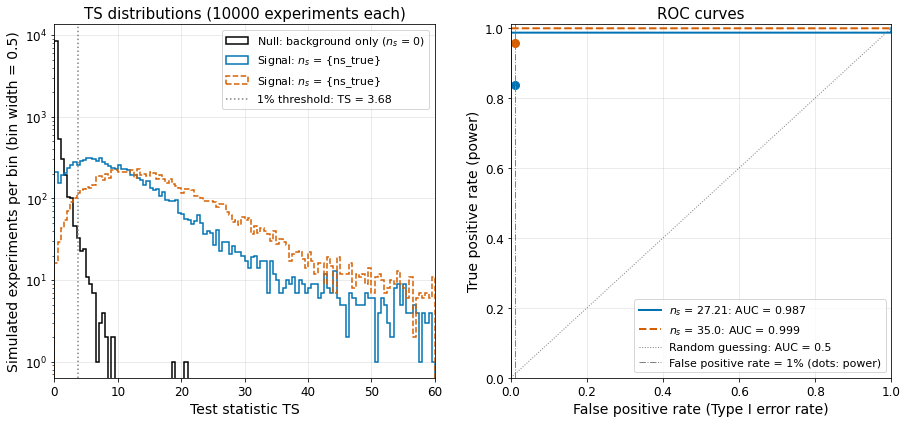

In [21]:
TS_NULL_FILE = "TS_simulated.npy" # TS of the 10k background-only

N_EXPERIMENTS = 10000 # I used 100 when I first wrote this
NS_VALUES = [27.21, 35.0]
ALPHA = 0.01 # Type I error 

# Fixed shape parameters
E0 = 206.0
GAMMA = 21.84
EB = 100.0

N = np.loadtxt(DATA_FILE).size
TS_null = np.load(TS_NULL_FILE)[:N_EXPERIMENTS]

rng = np.random.default_rng(seed=12)

def m2lnL(params, E):
    ns = params[0]
    fs = 1.0 / (np.pi * GAMMA * (1.0 + ((E - E0) / GAMMA) ** 2))
    fB = np.exp(-E / EB) / EB
    f = (ns / N) * fs + ((N - ns) / N) * fB
    return -2.0 * np.sum(np.log(f))

def test_statistic(E):
    result = minimize(m2lnL, [40.0], args=(E,), bounds=[(0.0, N)])
    return m2lnL([0.0], E) - result.fun

def simulate_signal_experiment(ns_true):
    n_signal = rng.binomial(N, ns_true / N)
    n_background = N - n_signal

    # Bacground photons
    background = rng.exponential(scale=EB, size=n_background)

    # Signal photons
    signal = E0 + GAMMA * rng.standard_cauchy(size=n_signal)
    while np.any(signal < 0):
        negative = signal < 0
        signal[negative] = E0 + GAMMA * rng.standard_cauchy(size=np.sum(negative))

    return np.concatenate([signal, background])

def roc_curve(TS_null, TS_signal):
    thresholds = np.unique(np.concatenate([TS_null, TS_signal]))[::-1]
    fpr = [0.0] # threshold above every TS
    tpr = [0.0]
    for t in thresholds:
        fpr.append(np.mean(TS_null) >= t)
        tpr.append(np.mean(TS_signal >= t))
    return np.array(fpr), np.array(tpr)

def area_under_curve(x, y):
    return np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2.0)

# Threshold for a 1% type I error
TS_threshold = np.percentile(TS_null, 100 * (1 - ALPHA))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
colors = ["#0072B2", "#D55E00"]
styles = ["-", "--"]

bins = np.linspace(0, 60, 121)
ax1.hist(TS_null, bins=bins, histtype="step", color="black", linewidth=1.5, label=r"Null: background only ($n_s$ = 0)")

for k in range(len(NS_VALUES)):
    ns_true = NS_VALUES[k]

    TS_signal = np.zeros(N_EXPERIMENTS)
    for i in range(N_EXPERIMENTS):
        E = simulate_signal_experiment(ns_true)
        TS_signal[i] = test_statistic(E)

    fpr, tpr = roc_curve(TS_null, TS_signal)
    auc = area_under_curve(fpr, tpr)

    # Check the AUC another way by comparing random pairs of (signal, null) experiments
    i_signal = rng.integers(0, N_EXPERIMENTS, size=1_000_000)
    i_null = rng.integers(0, N_EXPERIMENTS, size=1_000_000)
    wins = np.mean(TS_signal[i_signal] > TS_null[i_null])
    ties = np.mean(TS_signal[i_signal] == TS_null[i_null])
    auc_check = wins + 0.5 * ties

    power = np.mean(TS_signal > TS_threshold)

    print(f"=== True ns = {ns_true} ===")
    print(f"Median TS of the signal experiments = {np.median(TS_signal):.2f}")
    print(f"Signal experiments with TS = 0: {np.sum(TS_signal < 1e-6)}")
    print(f"Signal experiments with TS = infinity: {np.sum(np.isinf(TS_signal))}")
    print(f"AUC (area under the ROC curve) = {auc:.4f}")
    print(f"AUC check (random pairs) = {auc_check:.4f}")
    print(f"Power at the 1% threshold (TS > {TS_threshold:.2f}) = {power:.4f}")
    print()

    ax1.hist(TS_signal, bins=bins, histtype="step", color=colors[k], linewidth=1.5, linestyle=styles[k], label=r"Signal: $n_s$ = {ns_true}")
    ax2.plot(fpr, tpr, color=colors[k], linewidth=2, linestyle=styles[k], label=rf"$n_s$ = {ns_true}: AUC = {auc:.3f}")
    ax2.plot(ALPHA, power, "o", color=colors[k], markersize=8)

# TS distributions (left)
ax1.axvline(TS_threshold, color="gray", linewidth=1.5, linestyle=":", label=f"1% threshold: TS = {TS_threshold:.2f}")
ax1.set_xlabel("Test statistic TS", fontsize=14)
ax1.set_ylabel("Simulated experiments per bin (bin width = 0.5)", fontsize=14)
ax1.set_title(f"TS distributions ({N_EXPERIMENTS} experiments each)", fontsize=15)
ax1.set_yscale("log")
ax1.set_xlim(0, 60)
ax1.tick_params(labelsize=12)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

# ROC curves (right)
ax2.plot([0, 1], [0, 1], color="gray", linewidth=1, linestyle=":", label="Random guessing: AUC = 0.5")
ax2.axvline(ALPHA, color="gray", linewidth=1, linestyle="-.", label="False positive rate = 1% (dots: power)")
ax2.set_xlabel("False positive rate (Type I error rate)", fontsize=14)
ax2.set_ylabel("True positive rate (power)", fontsize=14)
ax2.set_title("ROC curves", fontsize=15)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1.01)
ax2.tick_params(labelsize=12)
ax2.legend(fontsize=11, loc="lower right")
ax2.grid(alpha=0.3)

The code first reuses what I did earlier. The m2lnL is from the likelihood analysis, and the test_statistic is the calculation as done in part 6, but wrapped in function so they can run 20k times. The null TS values are also loaded from the file in part 8. 

A lot of these things I never bothered to re-enter into the separate cells because since they're all in the same file, they all recognize what is being called, and I don't want to retype things when I don't have to.

After that, it then simulates experiments with signal. First it looks at how many signal photons there are, and reaches the conclusion that each of the 334 photons is signal with probability $n_s/N$ as the likelihood model already assumed.

The rng.binomial function draws the count for each experiment, so it averages 27.21, but varies from one experiment to the next. This also handles 27.21 not being a whole number.

For the background photons, each is drawn from the exponential, as in part 7, and the signal photons are drawn from the Wigner as $E0 + \Gamma \times (\text{standard Cauchy number})$.

The negative energies are about $3.4\%$ of Wigner draws come out below zero, which is impossible for a photon, so the while loop redraws them.

Then it builds the ROC curve, which uses every TS value, null, and signal together, as a threshold, from highest to lowest. At each one it records the two fractions above.

Then it calculates the AUC (area_under_curve), where the curve is points joined by straight lines, so the area between each point is just a trapezoid, which makes adding up the areas quite easy. It then checks is by picking a million random pairs and counts how often the signal experiment has the larger TS value, with ties counting as half.

After that, it then calculates the power at the $1\%$ threshold, which is the fraction of signal experiments above TS = 3.68, which was the threshold determined in part 9.

Now, for part 13, how many hours did I need to complete this project?

A lot. A lot of hours. I think I started this on November 1st, as it was a few days after it was released, and I finished on November 9th (spent the next two days writing up my report). I spent about 2-3 hours per day on it, so 9 days $\times$ 2-3 hours per day, and you get 18-27 hours in total, or an arithmetic average of 22.5 hours in total to complete the project.